<center><h1>Zuo_Xiyi_HW6</h1></center>
<br>
<center><font size="4">Tree-Based Methods on the APS Failure Data, and ISLR Exercises</font></center>

**Name:** Xiyi Zuo

**GitHub Username:** Kiera111

**USC ID:** 9330953458


### Package imports

All dependencies are imported in this cell so the notebook can be run from a clean kernel with Run All.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 180)
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 552
TRAIN_PATH = "../data/aps_failure_training_set.csv"
TEST_PATH = "../data/aps_failure_test_set.csv"
CV_FOLDS = 5
RF_TREES = 200
XGB_TREES = 200
ALPHAS = [0.0, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
# Scania's published costs: an unnecessary workshop check, and a missed failure.
APS_COST_FP = 10
APS_COST_FN = 500


## 1. Tree-Based Methods

### (a) Data

The APS Failure at Scania Trucks files are the training and test sets supplied with the homework. Each file begins with a 20-line preamble, and the column names are on the next line. The response `class` is `pos` for a failure of the specific APS component and `neg` for a failure somewhere else. The other 170 columns are anonymous numeric counters and histogram bins. Missing entries are stored as the token `na`.


In [2]:
train_raw = pd.read_csv(TRAIN_PATH, skiprows=20, na_values="na")
test_raw = pd.read_csv(TEST_PATH, skiprows=20, na_values="na")
feature_names = [column for column in train_raw.columns if column != "class"]

print(f"Training shape: {train_raw.shape}")
print(f"Test shape: {test_raw.shape}")
print(f"Number of predictors: {len(feature_names)}")
display(train_raw[feature_names].head(3))


Training shape: (60000, 171)
Test shape: (16000, 171)
Number of predictors: 170


,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,ag_008,ag_009,ah_000,ai_000,aj_000,ak_000,...,dv_000,dx_000,dy_000,dz_000,ea_000,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,76698,NaN,2.1307e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,25896.0,0.0,2551696.0,0.0,0.0,0.0,...,1876644.0,0.0,0.0,0.0,0.0,2801180.0,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,33058,NaN,0.0000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,31642.0,0.0,1393352.0,0.0,68.0,0.0,...,868538.0,0.0,0.0,0.0,0.0,3477820.0,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,41040,NaN,2.2800e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,12016.0,0.0,1234132.0,0.0,0.0,0.0,...,48028.0,0.0,0.0,0.0,0.0,1040120.0,1018.64,1020.0,262032.0,453378.0,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0


### (b) Data preparation

#### (i) Missing values

Rows with missing fields can be deleted, or the holes can be filled. The usual filling methods are:

- A single summary of the observed column: the mean, the median, or the mode.
- A donor row, as in hot-deck imputation, or the average of nearby rows, as in k-nearest-neighbor imputation.
- A multivariate model of each column given the others, repeated until the filled values settle. Multiple imputation by chained equations is the standard version.
- A split rule that sends a missing coordinate down its own branch. That option exists in some tree programs. scikit-learn's random forest needs a numeric value in every cell.

Deleting incomplete rows is a poor fit here: the count below shows that almost every training row has at least one missing entry, while only about 8 percent of the cells are missing. Throwing out a row because one histogram bin was not recorded would leave almost no sample. Nearest-neighbor and chained-equation imputation are also a poor fit at this size. Distances are unreliable when different rows are missing different coordinates, and cycling a model through 170 columns is a large amount of extra computation for a preprocessing step.

I use the column median. The predictors are counters and histogram bins, so their distributions are skewed and a few very large counts would pull a mean away from a typical truck. The median stays at a typical observed value. The medians are estimated on the training set and then reused for the test set. The homework footnote says that a deployed checker fills in a new truck without going back to the raw training table. Storing the training medians is that procedure: the test rows do not get to change the fill values, and the test labels are not used.


In [3]:
train_missing = train_raw[feature_names].isna()
test_missing = test_raw[feature_names].isna()
n_train_cells = train_missing.shape[0] * train_missing.shape[1]
n_test_cells = test_missing.shape[0] * test_missing.shape[1]
missing_summary = pd.DataFrame(
    {
        "training": [
            int(train_missing.to_numpy().sum()),
            train_missing.to_numpy().mean(),
            int((train_missing.mean() > 0).sum()),
            int((train_missing.mean() == 1).sum()),
            int(train_missing.any(axis=1).sum()),
            train_missing.any(axis=1).mean(),
        ],
        "test": [
            int(test_missing.to_numpy().sum()),
            test_missing.to_numpy().mean(),
            int((test_missing.mean() > 0).sum()),
            int((test_missing.mean() == 1).sum()),
            int(test_missing.any(axis=1).sum()),
            test_missing.any(axis=1).mean(),
        ],
    },
    index=[
        "missing cells",
        "share of cells missing",
        "features with any missing value",
        "features with every value missing",
        "rows with any missing value",
        "share of rows with any missing value",
    ],
)
display(missing_summary)

imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_train = imputer.fit_transform(train_raw[feature_names])
X_test = imputer.transform(test_raw[feature_names])
if np.isnan(X_train).any() or np.isnan(X_test).any():
    # A column with no observed training value has no median. None occurs in this file.
    X_train = np.nan_to_num(X_train, nan=0.0)
    X_test = np.nan_to_num(X_test, nan=0.0)

X_train_df = pd.DataFrame(X_train, columns=feature_names)
X_test_df = pd.DataFrame(X_test, columns=feature_names)
y_train = (train_raw["class"].to_numpy() == "pos").astype(np.int32)
y_test = (test_raw["class"].to_numpy() == "pos").astype(np.int32)
X_train_model = X_train_df.to_numpy(dtype=np.float32)
X_test_model = X_test_df.to_numpy(dtype=np.float32)

print(f"Imputed training matrix: {X_train_model.shape}")
print(f"Imputed test matrix: {X_test_model.shape}")
print(f"Remaining missing values: {np.isnan(X_train_model).sum() + np.isnan(X_test_model).sum()}")


,training,test
missing cells,850015.0000,228680.0000
share of cells missing,0.0833,0.0841
features with any missing value,169.0000,169.0000
features with every value missing,0.0000,0.0000
rows with any missing value,59409.0000,15835.0000
share of rows with any missing value,0.9901,0.9897


Imputed training matrix: (60000, 170)
Imputed test matrix: (16000, 170)
Remaining missing values: 0


#### (ii) Coefficient of variation

For each of the 170 imputed training features, the coefficient of variation is

$$
CV = \frac{s}{m},
$$

where \(m\) is the sample mean and \(s\) is the sample standard deviation with divisor \(n-1\). A feature whose mean is 0 has an undefined coefficient under this formula, so it is left out of the ranking. A large value means the feature spreads a lot relative to its typical level. It does not by itself measure association with the class label.


In [4]:
means = X_train_df.mean()
stds = X_train_df.std(ddof=1)
cv = stds / means.replace(0, np.nan)
cv_table = pd.DataFrame({"mean": means, "std": stds, "cv": cv})
cv_table["missing_rate_before_imputation"] = train_raw[feature_names].isna().mean()
undefined_cv = cv_table["cv"].isna()
print(f"Features with an undefined CV: {int(undefined_cv.sum())}")
if undefined_cv.any():
    display(cv_table.loc[undefined_cv, ["mean", "std", "cv"]])

n_visual = int(np.floor(np.sqrt(len(feature_names))))
print(f"floor(sqrt({len(feature_names)})) = {n_visual}")
top_cv = (
    cv_table.loc[~undefined_cv]
    .sort_values("cv", ascending=False)
    .head(n_visual)
    .copy()
)
top_cv.insert(0, "rank", np.arange(1, n_visual + 1))
top_features = top_cv.index.tolist()
display(top_cv)


Features with an undefined CV: 0
floor(sqrt(170)) = 13


,rank,mean,std,cv,missing_rate_before_imputation
cf_000,1,143107.5341,3.5045e+07,244.8875,0.2477
co_000,2,143330.0177,3.5045e+07,244.5074,0.2477
ad_000,3,143438.2921,3.5045e+07,244.3228,0.2477
cs_009,4,770.5097,1.8333e+05,237.9306,0.0112
dh_000,5,4392.6408,5.4124e+05,123.2161,0.0668
dj_000,6,37.2713,4.3792e+03,117.4942,0.0668
ag_000,7,219.1577,2.0364e+04,92.9178,0.0112
as_000,8,125.4079,1.0952e+04,87.3325,0.0105
ay_009,9,1149.6196,9.7412e+04,84.7337,0.0112
ak_000,10,907.6607,7.2999e+04,80.4250,0.0733


#### (iii) Correlation matrix

The heatmap uses Pearson correlation on the imputed training features, in the column order of the file. Histogram bins that belong to the same measurement sit next to each other, so a band of high correlation is the expected pattern. Correlation among predictors is not the same as usefulness for telling `pos` from `neg`.


Largest |correlation| off the diagonal: 1.0000 between bv_000 and cq_000
Median |correlation| off the diagonal: 0.0750
Share of feature pairs with |correlation| > 0.9: 0.0092
Features with zero variance after imputation: ['cd_000']
A constant feature has an undefined correlation with every column. Those cells are blank in the heatmap.


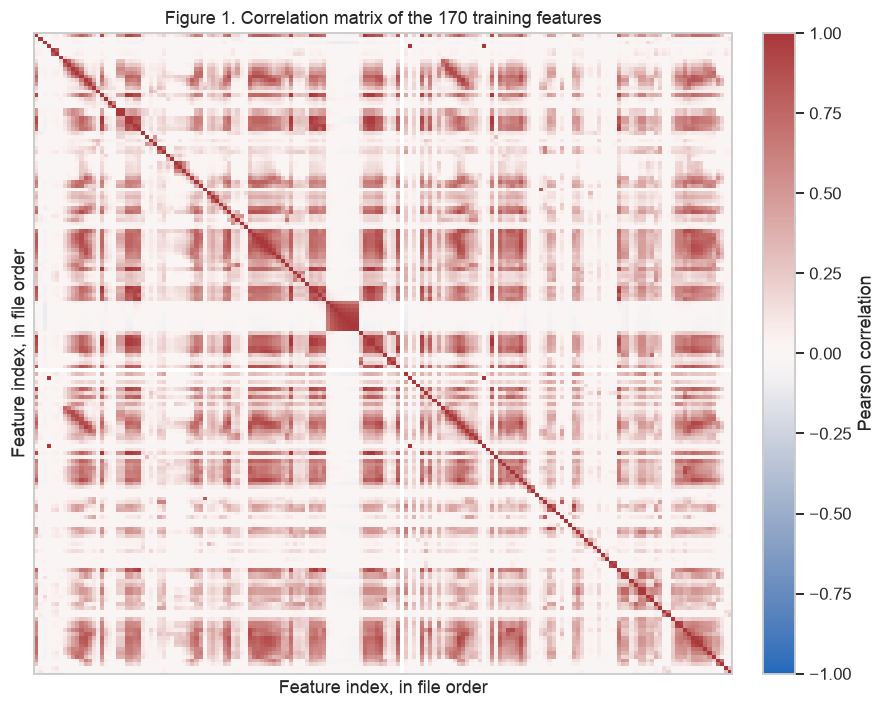

In [5]:
correlation = X_train_df.corr(method="pearson")
off_diagonal = correlation.where(~np.eye(correlation.shape[0], dtype=bool))
off_values = off_diagonal.to_numpy()
finite_mask = np.isfinite(off_values)
max_position = np.nanargmax(np.abs(off_values))
max_row, max_col = np.unravel_index(max_position, off_values.shape)
abs_off = np.abs(off_values[finite_mask])

print(
    f"Largest |correlation| off the diagonal: {off_values[max_row, max_col]:.4f} "
    f"between {correlation.index[max_row]} and {correlation.columns[max_col]}"
)
print(f"Median |correlation| off the diagonal: {np.median(abs_off):.4f}")
print(f"Share of feature pairs with |correlation| > 0.9: {np.mean(abs_off > 0.9):.4f}")
constant_features = X_train_df.columns[X_train_df.std(ddof=1) == 0].tolist()
print(f"Features with zero variance after imputation: {constant_features or 'none'}")
print(
    "A constant feature has an undefined correlation with every column. "
    "Those cells are blank in the heatmap."
)

fig, ax = plt.subplots(figsize=(8.2, 6.6))
image = ax.imshow(
    correlation.to_numpy(),
    cmap="vlag",
    vmin=-1,
    vmax=1,
    interpolation="nearest",
    aspect="auto",
)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("Feature index, in file order")
ax.set_ylabel("Feature index, in file order")
ax.set_title("Figure 1. Correlation matrix of the 170 training features")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label="Pearson correlation")
fig.tight_layout()
plt.show()


#### (iv) Scatter plots and boxplots of the highest-CV features

The \(\lfloor\sqrt{170}\rfloor = 13\) features above are used only in this visualization. Every later model is fit on all 170 features.

The scatterplot matrix shows each pair once. It contains all 1,000 positive training rows and 1,000 negative rows drawn at random, so the rare class is visible. Plotting all 59,000 negative rows would paint over the failures. The boxplots use every training row. Points beyond the whiskers are omitted; otherwise a handful of huge counts compresses every box onto the axis.


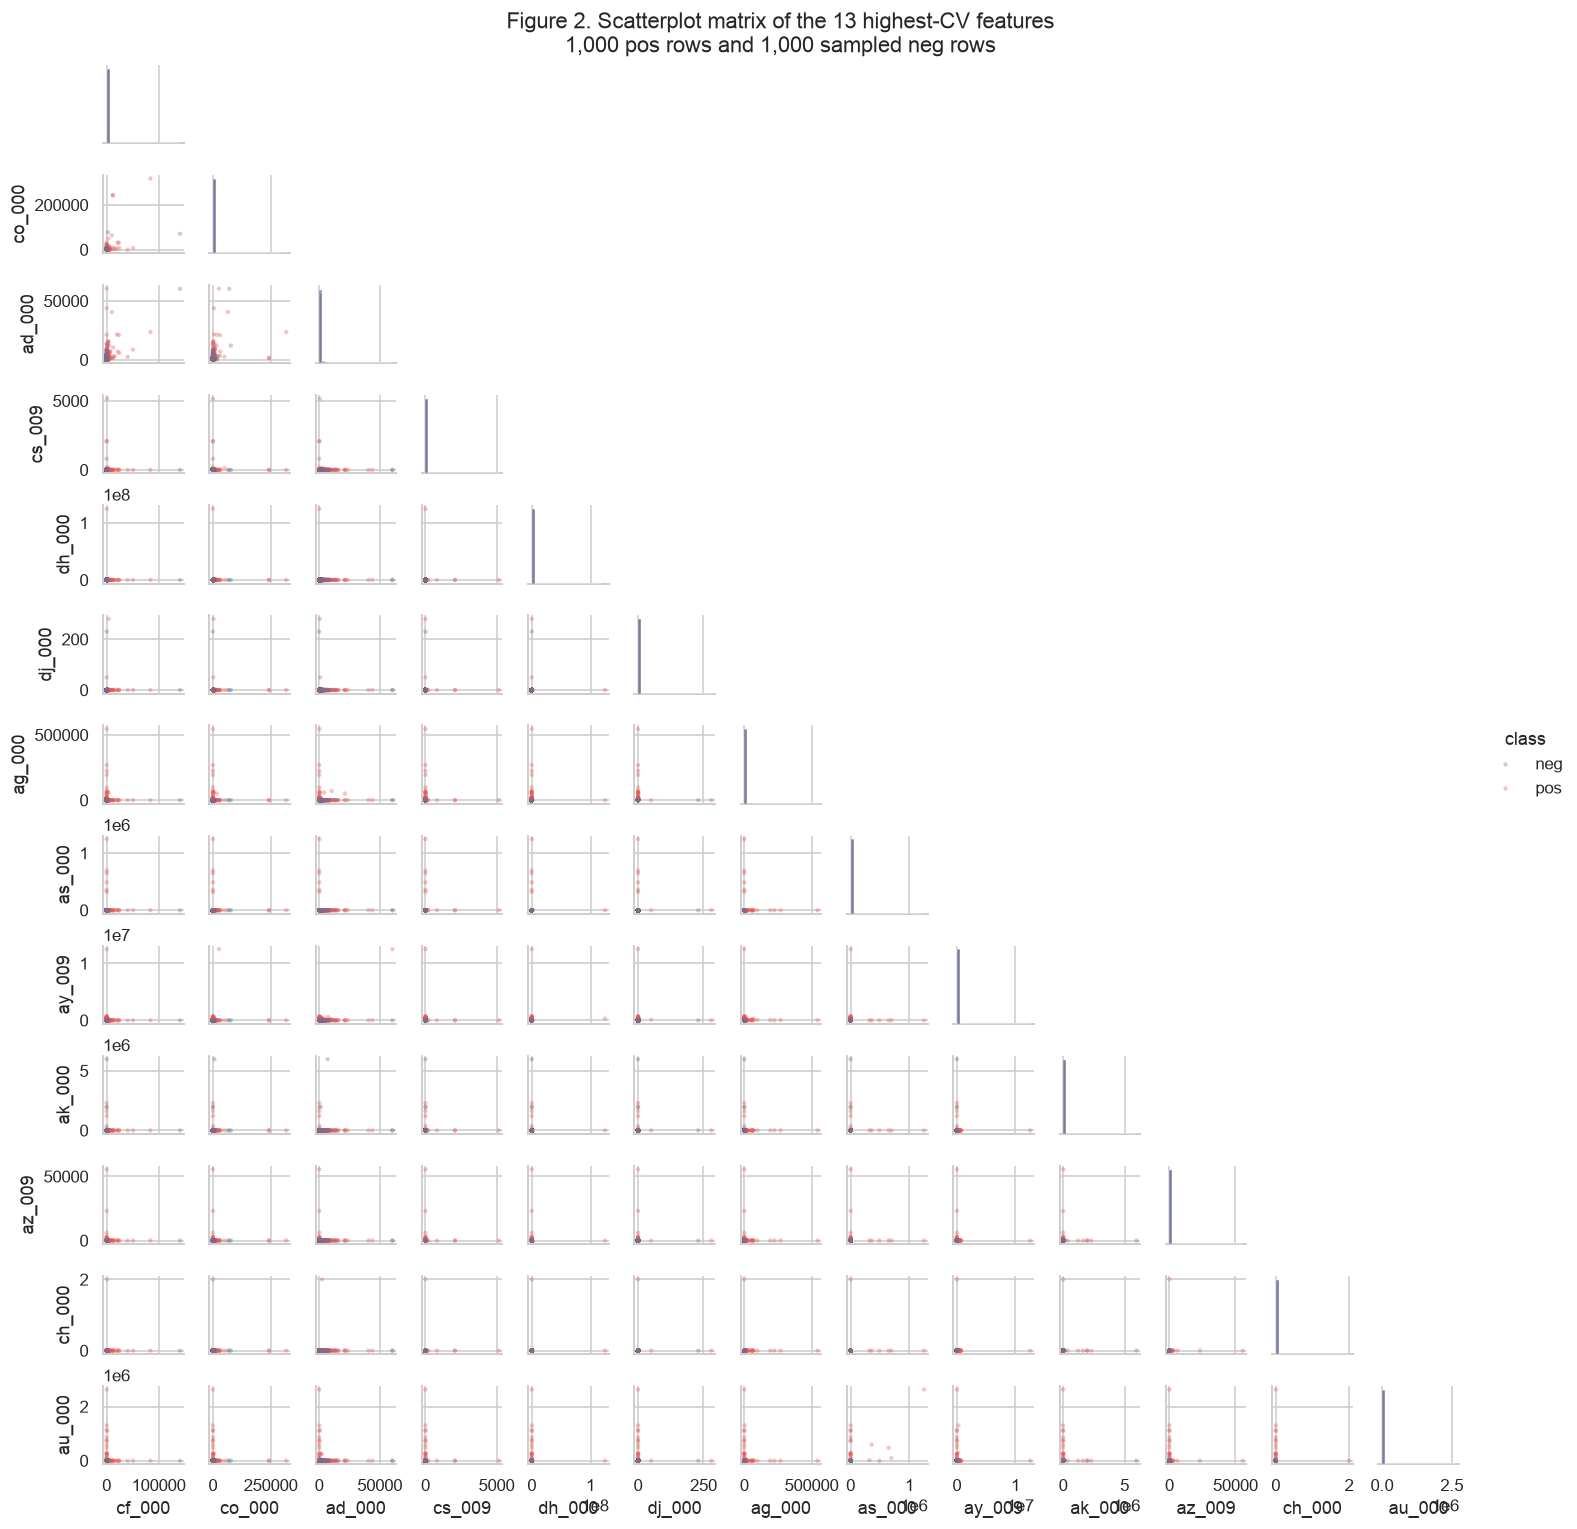

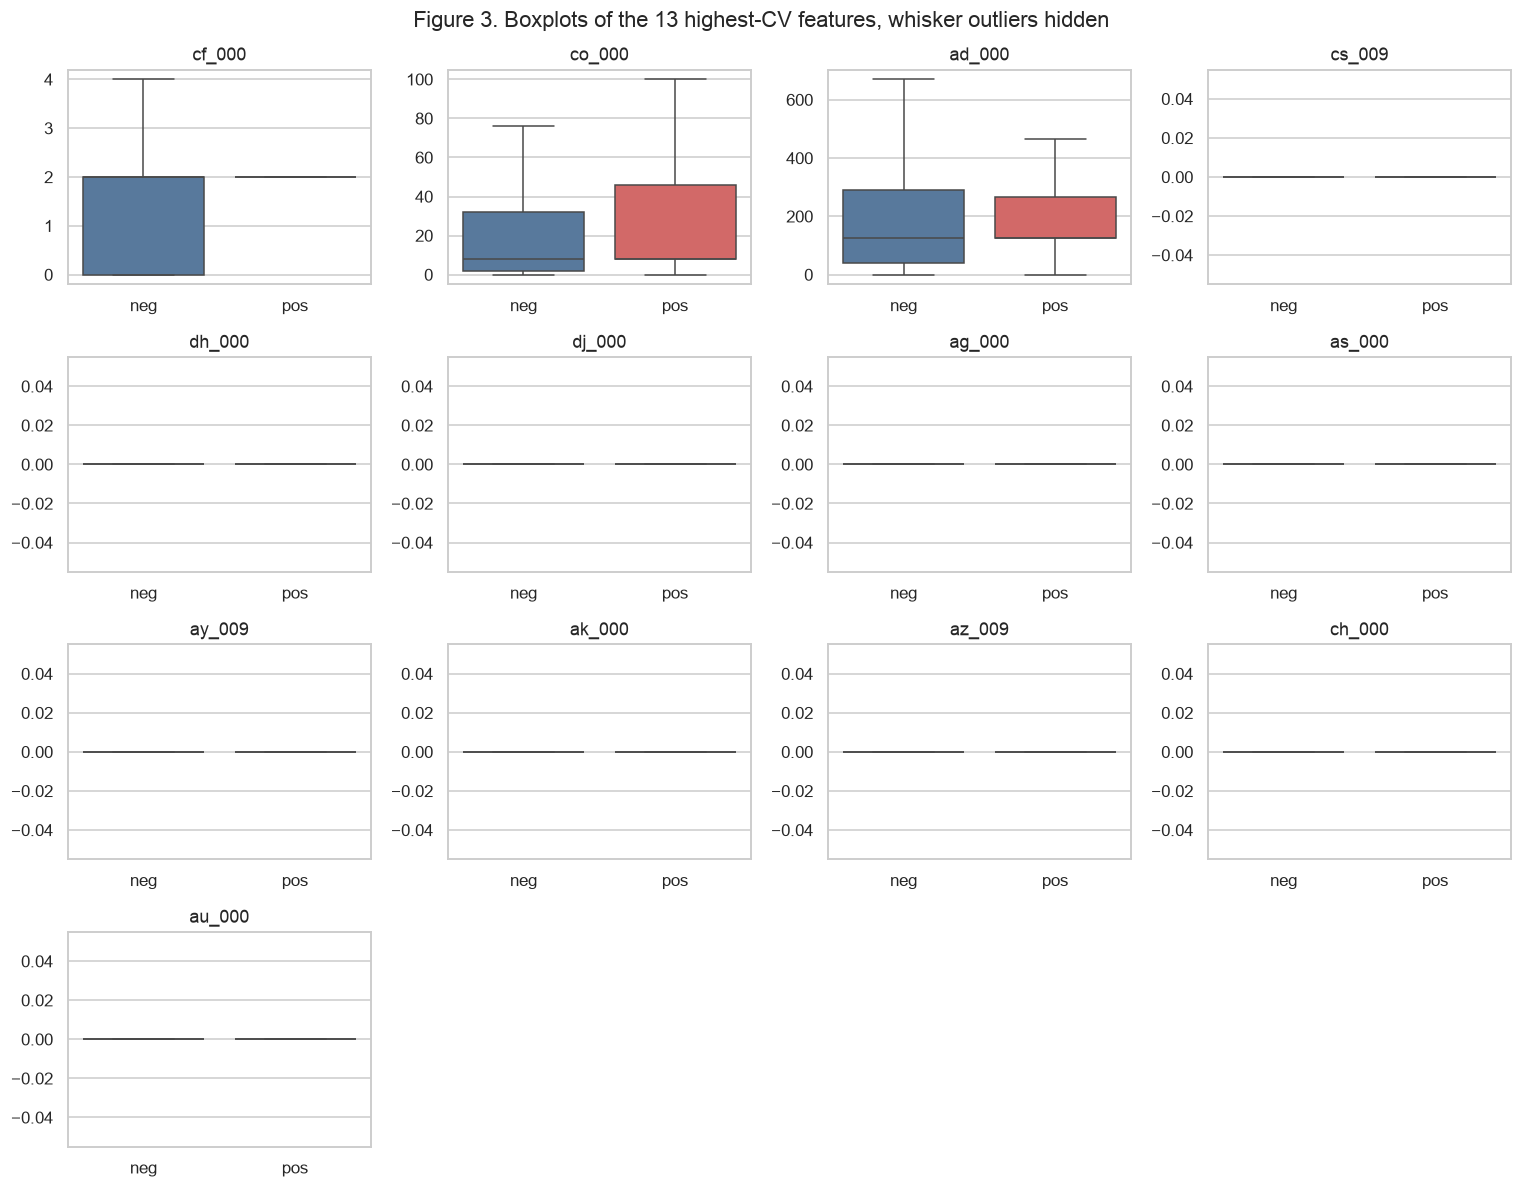

,median_neg,median_pos,median_gap,iqr,median_gap_over_iqr
feature,,,,,
cf_000,2.0,2.0,0.0,2.0,0.0
co_000,8.0,8.0,0.0,30.0,0.0
ad_000,126.0,126.0,0.0,250.0,0.0
cs_009,0.0,0.0,0.0,0.0,NaN
dh_000,0.0,0.0,0.0,0.0,NaN
dj_000,0.0,0.0,0.0,0.0,NaN
ag_000,0.0,0.0,0.0,0.0,NaN
as_000,0.0,0.0,0.0,0.0,NaN
ay_009,0.0,0.0,0.0,0.0,NaN


10 of these 13 features have IQR 0. Both classes have the same median, and for the zero-IQR features that median is 0. The large coefficient of variation comes from a few extreme counts, not from a shift between classes.
The scatter plots and boxplots therefore do not show that these features separate pos from neg. Coefficient of variation does not use the class label, so a high rank is not evidence of importance. These 13 columns are for the figures only. The classifiers below use all 170 features.


In [6]:
rng = np.random.default_rng(RANDOM_STATE)
positive_index = np.flatnonzero(y_train == 1)
negative_index = np.flatnonzero(y_train == 0)
negative_draw = rng.choice(negative_index, size=positive_index.size, replace=False)
sample_index = np.concatenate([positive_index, negative_draw])
rng.shuffle(sample_index)

scatter_frame = X_train_df.iloc[sample_index][top_features].copy()
scatter_frame["class"] = np.where(y_train[sample_index] == 1, "pos", "neg")
pair_grid = sns.pairplot(
    scatter_frame,
    hue="class",
    hue_order=["neg", "pos"],
    palette={"neg": "#4C78A8", "pos": "#E45756"},
    corner=True,
    diag_kind="hist",
    plot_kws={"s": 8, "alpha": 0.35, "linewidth": 0},
    diag_kws={"bins": 25, "alpha": 0.7},
    height=1.05,
)
pair_grid.fig.suptitle(
    "Figure 2. Scatterplot matrix of the 13 highest-CV features\n"
    "1,000 pos rows and 1,000 sampled neg rows",
    y=1.02,
)
plt.show()

long_frame = X_train_df[top_features].copy()
long_frame["class"] = np.where(y_train == 1, "pos", "neg")
long_frame = long_frame.melt(id_vars="class", var_name="feature", value_name="value")
fig, axes = plt.subplots(4, 4, figsize=(14, 11))
for axis, feature in zip(axes.ravel(), top_features):
    sns.boxplot(
        data=long_frame.loc[long_frame["feature"] == feature],
        x="class",
        y="value",
        order=["neg", "pos"],
        hue="class",
        hue_order=["neg", "pos"],
        palette={"neg": "#4C78A8", "pos": "#E45756"},
        legend=False,
        showfliers=False,
        ax=axis,
    )
    axis.set_title(feature)
    axis.set_xlabel("")
    axis.set_ylabel("")
for axis in axes.ravel()[len(top_features):]:
    axis.axis("off")
fig.suptitle("Figure 3. Boxplots of the 13 highest-CV features, whisker outliers hidden")
fig.tight_layout()
plt.show()

shift_rows = []
for feature in top_features:
    positive_values = X_train_df.loc[y_train == 1, feature]
    negative_values = X_train_df.loc[y_train == 0, feature]
    q75, q25 = np.percentile(X_train_df[feature], [75, 25])
    iqr = q75 - q25
    median_gap = positive_values.median() - negative_values.median()
    shift_rows.append(
        {
            "feature": feature,
            "median_neg": negative_values.median(),
            "median_pos": positive_values.median(),
            "median_gap": median_gap,
            "iqr": iqr,
            "median_gap_over_iqr": median_gap / iqr if iqr > 0 else np.nan,
        }
    )
shift_table = pd.DataFrame(shift_rows).set_index("feature")
display(shift_table)

zero_iqr = int((shift_table["iqr"] == 0).sum())
print(
    f"{zero_iqr} of these {len(shift_table)} features have IQR 0. "
    "Both classes have the same median, and for the zero-IQR features that median is 0. "
    "The large coefficient of variation comes from a few extreme counts, not from a shift between classes."
)
print(
    "The scatter plots and boxplots therefore do not show that these features separate pos from neg. "
    "Coefficient of variation does not use the class label, so a high rank is not evidence of importance. "
    "These 13 columns are for the figures only. The classifiers below use all 170 features."
)


#### (v) Positive and negative counts

`pos` is the failure of the APS component of interest. A data set this far from a 50/50 split is imbalanced: a rule that always says `neg` is already right on almost every row, and that rule finds none of the failures.


In [7]:
def class_count_table(labels, split_name):
    negative = int(np.sum(labels == 0))
    positive = int(np.sum(labels == 1))
    total = negative + positive
    return {
        "split": split_name,
        "neg": negative,
        "pos": positive,
        "total": total,
        "pos_share": positive / total,
        "always_neg_error": positive / total,
    }

class_counts = pd.DataFrame(
    [
        class_count_table(y_train, "training"),
        class_count_table(y_test, "test"),
    ]
).set_index("split")
display(class_counts)
print(
    "The training set has 1,000 failures and 59,000 other trucks. "
    "The test set has 375 failures and 15,625 other trucks. "
    "Both splits are severely imbalanced. The misclassification rate of a classifier "
    "that always predicts neg is the positive share in this table."
)


,neg,pos,total,pos_share,always_neg_error
split,,,,,
training,59000,1000,60000,0.0167,0.0167
test,15625,375,16000,0.0234,0.0234


The training set has 1,000 failures and 59,000 other trucks. The test set has 375 failures and 15,625 other trucks. Both splits are severely imbalanced. The misclassification rate of a classifier that always predicts neg is the positive share in this table.


### Shared reporting for the classifiers

For every model I report the confusion matrix, the ROC curve, the AUC, and the misclassification rate on the original training rows and on the test set. The positive class in the ROC is `pos`. The decision threshold is 0.5, which is the threshold used by `predict`.

Misclassification counts a false alarm and a missed failure as the same kind of mistake. The data description does not. Predicting `pos` for a `neg` truck costs 10 (an unnecessary check). Predicting `neg` for a `pos` truck costs 500 (a missed failure). I report that APS cost next to the required error so the comparison is not only about accuracy. It is not the quantity the models are trained to minimize.

The out-of-bag error of a random forest is the misclassification rate of the out-of-bag vote, \(1 - \text{oob accuracy}\).


In [8]:
comparison_rows = []


def positive_scores(model, features):
    positive_column = list(model.classes_).index(1)
    return model.predict_proba(features)[:, positive_column]


def evaluate_split(model, features, labels):
    scores = positive_scores(model, features)
    predictions = model.predict(features)
    matrix = confusion_matrix(labels, predictions, labels=[0, 1])
    true_negative, false_positive, false_negative, true_positive = matrix.ravel()
    total = matrix.sum()
    false_positive_rate, true_positive_rate, _ = roc_curve(labels, scores)
    return {
        "matrix": pd.DataFrame(
            matrix,
            index=["Actual neg", "Actual pos"],
            columns=["Predicted neg", "Predicted pos"],
        ),
        "tn": int(true_negative),
        "fp": int(false_positive),
        "fn": int(false_negative),
        "tp": int(true_positive),
        "misclassification": (false_positive + false_negative) / total,
        "recall_pos": true_positive / (true_positive + false_negative),
        "auc": roc_auc_score(labels, scores),
        "aps_cost": APS_COST_FP * int(false_positive) + APS_COST_FN * int(false_negative),
        "fpr": false_positive_rate,
        "tpr": true_positive_rate,
    }


def report_fitted_model(model_name, model, figure_title, oob_error=None):
    train_metrics = evaluate_split(model, X_train_model, y_train)
    test_metrics = evaluate_split(model, X_test_model, y_test)
    print(model_name)
    print("Training confusion matrix")
    display(train_metrics["matrix"])
    print("Test confusion matrix")
    display(test_metrics["matrix"])

    fig, ax = plt.subplots(figsize=(5.6, 5.2))
    ax.plot(
        train_metrics["fpr"],
        train_metrics["tpr"],
        color="#4C78A8",
        label=f"Training AUC = {train_metrics['auc']:.3f}",
    )
    ax.plot(
        test_metrics["fpr"],
        test_metrics["tpr"],
        color="#E45756",
        label=f"Test AUC = {test_metrics['auc']:.3f}",
    )
    ax.plot([0, 1], [0, 1], linestyle="--", color="0.5", linewidth=1, label="Chance")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(figure_title)
    ax.legend(loc="lower right")
    fig.tight_layout()
    plt.show()

    for split_name, metrics in [("training", train_metrics), ("test", test_metrics)]:
        comparison_rows.append(
            {
                "model": model_name,
                "split": split_name,
                "misclassification": metrics["misclassification"],
                "recall_pos": metrics["recall_pos"],
                "auc": metrics["auc"],
                "fp": metrics["fp"],
                "fn": metrics["fn"],
                "tp": metrics["tp"],
                "tn": metrics["tn"],
                "aps_cost": metrics["aps_cost"],
                "oob_error": oob_error if split_name == "training" else np.nan,
            }
        )
    summary = pd.DataFrame(comparison_rows)
    display(
        summary.loc[summary["model"] == model_name]
        .drop(columns=["model"])
        .set_index("split")
    )
    return train_metrics, test_metrics


def describe_oob(model_name, train_metrics, test_metrics, oob_error):
    train_gap = abs(train_metrics["misclassification"] - test_metrics["misclassification"])
    oob_gap = abs(oob_error - test_metrics["misclassification"])
    closer = "OOB" if oob_gap <= train_gap else "training"
    print(
        f"{model_name}: training misclassification = {train_metrics['misclassification']:.4f}, "
        f"OOB error = {oob_error:.4f}, test misclassification = {test_metrics['misclassification']:.4f}. "
        f"The {closer} figure is closer to the test error "
        f"(absolute gaps {train_gap:.4f} for training and {oob_gap:.4f} for OOB)."
    )
    print(
        f"Positive-class recall is {train_metrics['recall_pos']:.4f} in training and "
        f"{test_metrics['recall_pos']:.4f} on the test set. Test AUC is {test_metrics['auc']:.4f}. "
        f"Test APS cost is {test_metrics['aps_cost']} "
        f"({test_metrics['fp']} false positives at {APS_COST_FP}, "
        f"{test_metrics['fn']} false negatives at {APS_COST_FN})."
    )


### (c) Random forest with no correction for imbalance

The forest is an ensemble of 200 unpruned trees grown on bootstrap samples. Each split considers \(\sqrt{170}\) randomly chosen features, which is scikit-learn's `max_features="sqrt"`. Class weights are left at their default, so the abundant `neg` class dominates the impurity calculations and the majority vote. `oob_score=True` turns on the out-of-bag accuracy; the out-of-bag error reported below is one minus that accuracy.


Out-of-bag accuracy: 0.9942
Out-of-bag error: 0.0058


Random forest, no class weight
Training confusion matrix


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,0,1000


Test confusion matrix


,Predicted neg,Predicted pos
Actual neg,15606,19
Actual pos,102,273


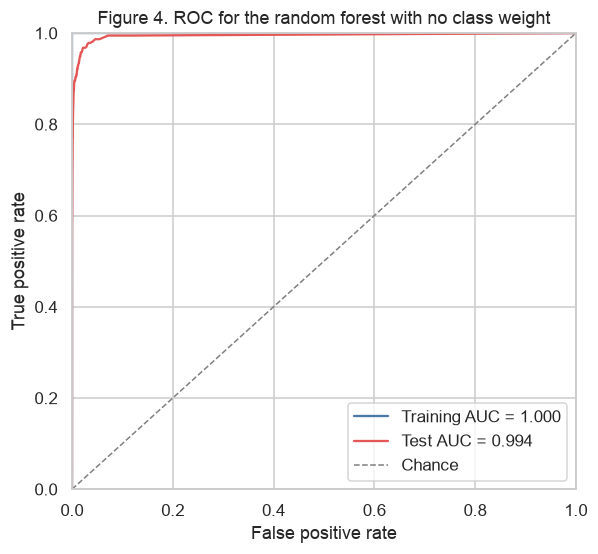

,misclassification,recall_pos,auc,fp,fn,tp,tn,aps_cost,oob_error
split,,,,,,,,,
training,0.0000,1.000,1.0000,0,0,1000,59000,0,0.0058
test,0.0076,0.728,0.9944,19,102,273,15606,51190,NaN


Random forest, no class weight: training misclassification = 0.0000, OOB error = 0.0058, test misclassification = 0.0076. The OOB figure is closer to the test error (absolute gaps 0.0076 for training and 0.0018 for OOB).
Positive-class recall is 1.0000 in training and 0.7280 on the test set. Test AUC is 0.9944. Test APS cost is 51190 (19 false positives at 10, 102 false negatives at 500).


In [9]:
forest_plain = RandomForestClassifier(
    n_estimators=RF_TREES,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
forest_plain.fit(X_train_model, y_train)
oob_error_plain = 1.0 - forest_plain.oob_score_
print(f"Out-of-bag accuracy: {forest_plain.oob_score_:.4f}")
print(f"Out-of-bag error: {oob_error_plain:.4f}")

train_plain, test_plain = report_fitted_model(
    "Random forest, no class weight",
    forest_plain,
    "Figure 4. ROC for the random forest with no class weight",
    oob_error=oob_error_plain,
)
describe_oob("Random forest, no class weight", train_plain, test_plain, oob_error_plain)


### (d) Random forest with a correction for imbalance

A random forest can respond to imbalance in three ways. The first is a class weight. With `class_weight="balanced"`, class \(c\) receives weight \(n / (k n_c)\), where \(n\) is the sample size, \(k\) is the number of classes, and \(n_c\) is the count of class \(c\). The minority class then contributes as much total weight as the majority class. `class_weight="balanced_subsample"` recomputes that weight inside each bootstrap sample, which matches the way a forest is grown. The second is resampling: draw a balanced bootstrap, or oversample the rare class before fitting. The third is to keep an ordinary forest and lower the probability threshold used to call `pos`.

I use `balanced_subsample`. The training rows are unchanged, the correction is applied inside every tree, and the out-of-bag vote remains defined. The rest of the settings match part (c).


Out-of-bag accuracy: 0.9923
Out-of-bag error: 0.0077


Random forest, balanced_subsample
Training confusion matrix


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,0,1000


Test confusion matrix


,Predicted neg,Predicted pos
Actual neg,15611,14
Actual pos,154,221


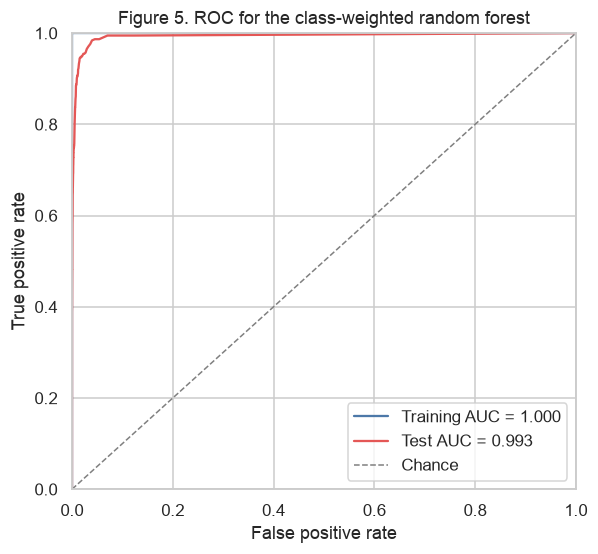

,misclassification,recall_pos,auc,fp,fn,tp,tn,aps_cost,oob_error
split,,,,,,,,,
training,0.0000,1.0000,1.0000,0,0,1000,59000,0,0.0077
test,0.0105,0.5893,0.9933,14,154,221,15611,77140,NaN


Random forest, balanced_subsample: training misclassification = 0.0000, OOB error = 0.0077, test misclassification = 0.0105. The OOB figure is closer to the test error (absolute gaps 0.0105 for training and 0.0028 for OOB).
Positive-class recall is 1.0000 in training and 0.5893 on the test set. Test AUC is 0.9933. Test APS cost is 77140 (14 false positives at 10, 154 false negatives at 500).
Comparison of the two forests on the test set:
No class weight: misclassification 0.0076, positive recall 0.7280, AUC 0.9944, FP 19, FN 102, APS cost 51190.
balanced_subsample: misclassification 0.0105, positive recall 0.5893, AUC 0.9933, FP 14, FN 154, APS cost 77140.
The weighted forest does not recover more failed trucks. Test recall falls from 0.7280 to 0.5893, false negatives rise from 102 to 154, and false positives only fall from 19 to 14.
The weighted forest also has the higher APS cost (77140 versus 51190). Reweighting the bootstrap samples changed the splits, but on this test set it did n

In [10]:
forest_balanced = RandomForestClassifier(
    n_estimators=RF_TREES,
    max_features="sqrt",
    class_weight="balanced_subsample",
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
forest_balanced.fit(X_train_model, y_train)
oob_error_balanced = 1.0 - forest_balanced.oob_score_
print(f"Out-of-bag accuracy: {forest_balanced.oob_score_:.4f}")
print(f"Out-of-bag error: {oob_error_balanced:.4f}")

train_balanced, test_balanced = report_fitted_model(
    "Random forest, balanced_subsample",
    forest_balanced,
    "Figure 5. ROC for the class-weighted random forest",
    oob_error=oob_error_balanced,
)
describe_oob(
    "Random forest, balanced_subsample",
    train_balanced,
    test_balanced,
    oob_error_balanced,
)

print("Comparison of the two forests on the test set:")
print(
    f"No class weight: misclassification {test_plain['misclassification']:.4f}, "
    f"positive recall {test_plain['recall_pos']:.4f}, AUC {test_plain['auc']:.4f}, "
    f"FP {test_plain['fp']}, FN {test_plain['fn']}, APS cost {test_plain['aps_cost']}."
)
print(
    f"balanced_subsample: misclassification {test_balanced['misclassification']:.4f}, "
    f"positive recall {test_balanced['recall_pos']:.4f}, AUC {test_balanced['auc']:.4f}, "
    f"FP {test_balanced['fp']}, FN {test_balanced['fn']}, APS cost {test_balanced['aps_cost']}."
)
if test_balanced["recall_pos"] > test_plain["recall_pos"]:
    print(
        "The weighted forest recovers more of the failed trucks. "
        "That gain comes from calling pos more often, so false positives move as well."
    )
else:
    print(
        "The weighted forest does not recover more failed trucks. "
        f"Test recall falls from {test_plain['recall_pos']:.4f} to {test_balanced['recall_pos']:.4f}, "
        f"false negatives rise from {test_plain['fn']} to {test_balanced['fn']}, "
        f"and false positives only fall from {test_plain['fp']} to {test_balanced['fp']}."
    )
if test_balanced["aps_cost"] < test_plain["aps_cost"]:
    print("The weighted forest has the lower APS cost on the test set.")
else:
    print(
        f"The weighted forest also has the higher APS cost "
        f"({test_balanced['aps_cost']} versus {test_plain['aps_cost']}). "
        "Reweighting the bootstrap samples changed the splits, but on this test set "
        "it did not improve the 0.5-threshold decisions. The test AUCs stay close, "
        f"{test_plain['auc']:.4f} without weights and {test_balanced['auc']:.4f} with weights, "
        "so the ranking of trucks is similar and the loss is mostly at the threshold."
    )
print(
    "Both forests have training misclassification 0, so the in-sample error cannot "
    "choose between them. The OOB error moves in the same direction as the test error: "
    f"from {oob_error_plain:.4f} to {oob_error_balanced:.4f}, against test errors "
    f"{test_plain['misclassification']:.4f} and {test_balanced['misclassification']:.4f}."
)


### (e) XGBoost and model trees, with no correction for imbalance

In an ordinary tree, the split at a node has the form \(X_j > s\). A model tree can use a linear score in all of the inputs, \(\sum_j \beta_j X_j > s\), and a regression tree can fit a linear model in each leaf instead of a constant. With 170 features, an unpenalized linear score at every node would be unstable, so the natural penalty is an L1 penalty with strength \(\alpha\).

XGBoost is the fitting method named in the question. I use `XGBClassifier` with the logistic objective `binary:logistic` and the L1 penalty `reg_alpha`. That penalty is \(\alpha\). The L2 penalty `reg_lambda` is held at 1, and the tree size is held fixed, so the cross-validation below changes only \(\alpha\). This is penalized gradient boosting with logistic loss, not a hand-written logistic regression inside every node. It is the XGBoost fit the question asks for on a problem with this many columns.

The other settings are 200 trees, depth 6, learning rate 0.1, row subsample 0.8, and column subsample 0.6. Nothing here reweights the classes or resamples them. `scale_pos_weight` stays at its default of 1.

\(\alpha\) is chosen by 5-fold stratified cross-validation. Leave-one-out would refit the booster once per training row, which is not a useful estimate on 60,000 rows. I select the \(\alpha\) with the highest mean validation AUC. Misclassification is a bad selection score on this split: the constant `neg` rule is already wrong on only 1.67 percent of the training rows. AUC uses the ranking of the predicted probabilities, which is what the ROC reports. The cross-validated misclassification of the selected model is still the error I compare with the test error. The same five folds produce both numbers. That CV error is slightly optimistic, because \(\alpha\) was chosen on those folds, and it is still a much more honest estimate than the in-sample training error.


Finished fold 1/5 (SMOTE inside fold: False)


Finished fold 2/5 (SMOTE inside fold: False)


Finished fold 3/5 (SMOTE inside fold: False)


Finished fold 4/5 (SMOTE inside fold: False)


Finished fold 5/5 (SMOTE inside fold: False)


Selected alpha without SMOTE: 0


... (2 outputs left out)

XGBoost, alpha=0, no SMOTE
Training confusion matrix


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,1,999


Test confusion matrix


,Predicted neg,Predicted pos
Actual neg,15610,15
Actual pos,86,289


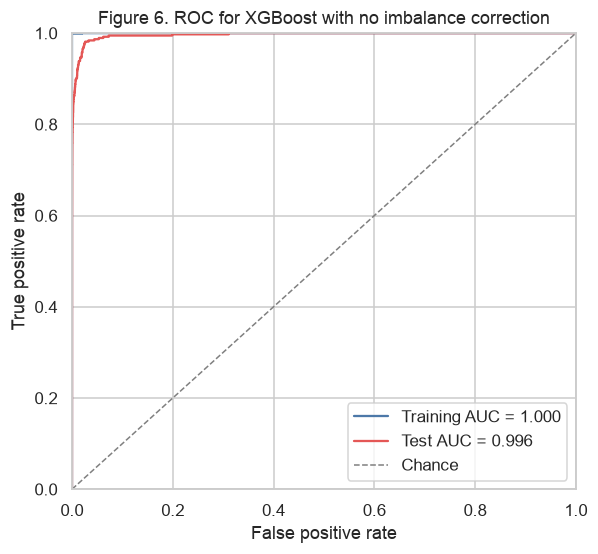

,misclassification,recall_pos,auc,fp,fn,tp,tn,aps_cost,oob_error
split,,,,,,,,,
training,1.6667e-05,0.9990,1.0000,0,1,999,59000,500,NaN
test,6.3125e-03,0.7707,0.9961,15,86,289,15610,43150,NaN


5-fold CV misclassification at alpha=0 is 0.0058. Test misclassification is 0.0063. In-sample training misclassification is 0.0000.
5-fold CV AUC is 0.9898, and test AUC is 0.9961. The CV misclassification is the error estimate to compare with the test error. The training misclassification is the fit to rows the booster has already seen.


In [11]:
def make_xgboost(alpha):
    return XGBClassifier(
        n_estimators=XGB_TREES,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.6,
        reg_lambda=1.0,
        reg_alpha=float(alpha),
        objective="binary:logistic",
        tree_method="hist",
        eval_metric="logloss",
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbosity=0,
    )


def cross_validate_alpha(features, labels, use_smote):
    """Choose reg_alpha. SMOTE, when requested, is fit inside each training fold."""
    splitter = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    )
    records = []
    for fold_id, (train_index, valid_index) in enumerate(splitter.split(features, labels), start=1):
        fold_features = features[train_index]
        fold_labels = labels[train_index]
        if use_smote:
            fold_features, fold_labels = SMOTE(random_state=RANDOM_STATE).fit_resample(
                fold_features,
                fold_labels,
            )
        valid_features = features[valid_index]
        valid_labels = labels[valid_index]
        for alpha in ALPHAS:
            booster = make_xgboost(alpha)
            booster.fit(fold_features, fold_labels)
            scores = positive_scores(booster, valid_features)
            predictions = booster.predict(valid_features)
            matrix = confusion_matrix(valid_labels, predictions, labels=[0, 1])
            false_positive = matrix[0, 1]
            false_negative = matrix[1, 0]
            records.append(
                {
                    "alpha": alpha,
                    "fold": fold_id,
                    "misclassification": (false_positive + false_negative) / matrix.sum(),
                    "auc": roc_auc_score(valid_labels, scores),
                }
            )
        print(f"Finished fold {fold_id}/{CV_FOLDS} (SMOTE inside fold: {use_smote})", flush=True)

    detail = pd.DataFrame(records)
    summary = (
        detail.groupby("alpha", as_index=False)
        .agg(
            cv_misclassification=("misclassification", "mean"),
            cv_misclassification_std=("misclassification", "std"),
            cv_auc=("auc", "mean"),
            cv_auc_std=("auc", "std"),
        )
        .sort_values(
            ["cv_auc", "cv_misclassification", "alpha"],
            ascending=[False, True, True],
        )
        .reset_index(drop=True)
    )
    best_alpha = float(summary.loc[0, "alpha"])
    by_alpha = summary.sort_values("alpha").reset_index(drop=True)
    return best_alpha, by_alpha


best_alpha_plain, cv_plain = cross_validate_alpha(X_train_model, y_train, use_smote=False)
print(f"Selected alpha without SMOTE: {best_alpha_plain:g}")
display(cv_plain)
small_alpha_auc = cv_plain.loc[cv_plain["alpha"] <= 1, "cv_auc"]
auc_span = float(small_alpha_auc.max() - small_alpha_auc.min())
print(
    f"Mean CV AUC changes by only {auc_span:.4f} across alpha from 0 to 1, "
    "which is smaller than the fold-to-fold standard deviation. "
    "Alpha 0 has the highest mean AUC. Alpha 100 is the setting that clearly "
    "raises the cross-validated misclassification."
)

xgboost_plain = make_xgboost(best_alpha_plain)
xgboost_plain.fit(X_train_model, y_train)
train_xgb, test_xgb = report_fitted_model(
    f"XGBoost, alpha={best_alpha_plain:g}, no SMOTE",
    xgboost_plain,
    "Figure 6. ROC for XGBoost with no imbalance correction",
)
cv_error_plain = float(
    cv_plain.loc[cv_plain["alpha"] == best_alpha_plain, "cv_misclassification"].iloc[0]
)
cv_auc_plain = float(cv_plain.loc[cv_plain["alpha"] == best_alpha_plain, "cv_auc"].iloc[0])
print(
    f"5-fold CV misclassification at alpha={best_alpha_plain:g} is {cv_error_plain:.4f}. "
    f"Test misclassification is {test_xgb['misclassification']:.4f}. "
    f"In-sample training misclassification is {train_xgb['misclassification']:.4f}."
)
print(
    f"5-fold CV AUC is {cv_auc_plain:.4f}, and test AUC is {test_xgb['auc']:.4f}. "
    "The CV misclassification is the error estimate to compare with the test error. "
    "The training misclassification is the fit to rows the booster has already seen."
)


### (f) SMOTE, then the same XGBoost model

SMOTE builds extra `pos` rows by interpolating a failure with one of its k nearest failure neighbors. I use the default of 5 neighbors and the default sampling strategy, which adds synthetic failures until the two classes have the same count. The test set is never passed to SMOTE.

There is a wrong way to combine this with cross-validation. If SMOTE is applied to all 60,000 training rows and the folds are cut afterward, synthetic rows in a validation fold were created with neighbors that can come from that same fold, and the validation error is no longer an error on real trucks. The right way, used here, is to cut the folds on the original training rows first. Inside each fold, SMOTE sees only the training portion. The validation portion keeps its original labels and its original class frequencies. The \(\alpha\) chosen by that cross-validation is then used to fit one final booster on a SMOTE version of the full training set. Training and test metrics for that final model are computed on the original rows, not on the synthetic sample.


Finished fold 1/5 (SMOTE inside fold: True)


Finished fold 2/5 (SMOTE inside fold: True)


Finished fold 3/5 (SMOTE inside fold: True)


Finished fold 4/5 (SMOTE inside fold: True)


Finished fold 5/5 (SMOTE inside fold: True)


Selected alpha with SMOTE inside each fold: 0


... (2 outputs left out)

XGBoost, alpha=0, SMOTE
Training confusion matrix


,Predicted neg,Predicted pos
Actual neg,58993,7
Actual pos,13,987


Test confusion matrix


,Predicted neg,Predicted pos
Actual neg,15566,59
Actual pos,60,315


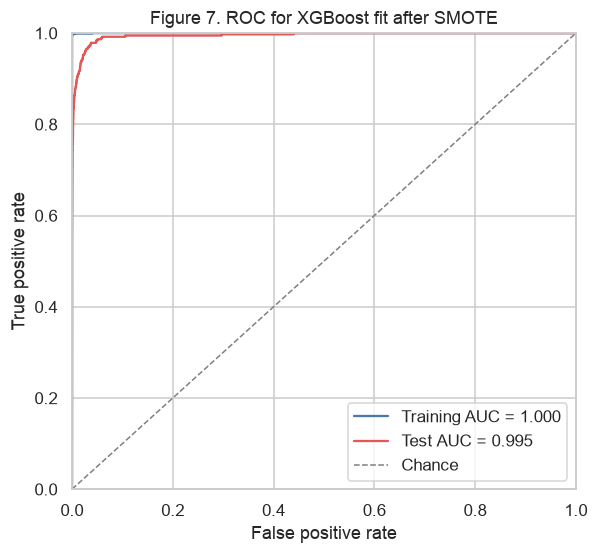

,misclassification,recall_pos,auc,fp,fn,tp,tn,aps_cost,oob_error
split,,,,,,,,,
training,0.0003,0.987,0.9999,7,13,987,58993,6570,NaN
test,0.0074,0.840,0.9947,59,60,315,15566,30590,NaN


5-fold CV misclassification at alpha=0 is 0.0071. Test misclassification is 0.0074. Misclassification on the original training rows is 0.0003.
5-fold CV AUC is 0.9887, and test AUC is 0.9947.
Comparison of XGBoost without SMOTE and XGBoost with SMOTE, on the test set:
No SMOTE (alpha=0): misclassification 0.0063, positive recall 0.7707, AUC 0.9961, FP 15, FN 86, APS cost 43150, CV error 0.0058.
SMOTE (alpha=0): misclassification 0.0074, positive recall 0.8400, AUC 0.9947, FP 59, FN 60, APS cost 30590, CV error 0.0071.
SMOTE raises recall of the failed trucks. The model sees an equal number of the two classes while it is fit, so the 0.5 threshold is no longer the threshold of a model that has seen 59 negative trucks for every failure.
The same change increases false positives: more trucks that do not have this APS failure are sent for a check.
On the Scania cost, the SMOTE model is the better of the two XGBoost fits, because missed failures dominate that sum.
For both XGBoost models, th

misclassification  recall_pos     auc  fp   fn    tp     tn  aps_cost  \
model                             split                                                                             
Random forest, no class weight    training         0.0000e+00      1.0000  1.0000   0    0  1000  59000         0   
                                  test             7.5625e-03      0.7280  0.9944  19  102   273  15606     51190   
Random forest, balanced_subsample training         0.0000e+00      1.0000  1.0000   0    0  1000  59000         0   
                                  test             1.0500e-02      0.5893  0.9933  14  154   221  15611     77140   
XGBoost, alpha=0, no SMOTE        training         1.6667e-05      0.9990  1.0000   0    1   999  59000       500   
                                  test             6.3125e-03      0.7707  0.9961  15   86   289  15610     43150   
XGBoost, alpha=0, SMOTE           training         3.3333e-04      0.9870  0.9999   7   13   987  58993      6570   
                                  test             7.4375e-03      0.8400  0.9947  59   60   315  15566     30590   

                                            oob_error  
model                             split                
Random forest, no class weight    training     0.0058  
                                  test            NaN  
Random forest, balanced_subsample training     0.0077  
                                  test            NaN  
XGBoost, alpha=0, no SMOTE        training        NaN  
                                  test            NaN  
XGBoost, alpha=0, SMOTE           training        NaN  
                                  test            NaN

In [12]:
best_alpha_smote, cv_smote = cross_validate_alpha(X_train_model, y_train, use_smote=True)
print(f"Selected alpha with SMOTE inside each fold: {best_alpha_smote:g}")
display(cv_smote)
small_alpha_auc_smote = cv_smote.loc[cv_smote["alpha"] <= 1, "cv_auc"]
auc_span_smote = float(small_alpha_auc_smote.max() - small_alpha_auc_smote.min())
print(
    f"With SMOTE inside the folds, mean CV AUC changes by only {auc_span_smote:.4f} "
    "across alpha from 0 to 1. Alpha 0 is again the maximizer, and alpha 100 is again "
    "the value that raises the cross-validated error."
)

X_smote, y_smote = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_model, y_train)
print(
    f"Full training set after SMOTE: {len(y_smote)} rows, "
    f"{int(np.sum(y_smote == 1))} pos and {int(np.sum(y_smote == 0))} neg. "
    f"The original training set had {len(y_train)} rows and {int(np.sum(y_train == 1))} pos."
)

xgboost_smote = make_xgboost(best_alpha_smote)
xgboost_smote.fit(X_smote, y_smote)
train_smote, test_smote = report_fitted_model(
    f"XGBoost, alpha={best_alpha_smote:g}, SMOTE",
    xgboost_smote,
    "Figure 7. ROC for XGBoost fit after SMOTE",
)
cv_error_smote = float(
    cv_smote.loc[cv_smote["alpha"] == best_alpha_smote, "cv_misclassification"].iloc[0]
)
cv_auc_smote = float(cv_smote.loc[cv_smote["alpha"] == best_alpha_smote, "cv_auc"].iloc[0])
print(
    f"5-fold CV misclassification at alpha={best_alpha_smote:g} is {cv_error_smote:.4f}. "
    f"Test misclassification is {test_smote['misclassification']:.4f}. "
    f"Misclassification on the original training rows is {train_smote['misclassification']:.4f}."
)
print(
    f"5-fold CV AUC is {cv_auc_smote:.4f}, and test AUC is {test_smote['auc']:.4f}."
)

print("Comparison of XGBoost without SMOTE and XGBoost with SMOTE, on the test set:")
print(
    f"No SMOTE (alpha={best_alpha_plain:g}): misclassification {test_xgb['misclassification']:.4f}, "
    f"positive recall {test_xgb['recall_pos']:.4f}, AUC {test_xgb['auc']:.4f}, "
    f"FP {test_xgb['fp']}, FN {test_xgb['fn']}, APS cost {test_xgb['aps_cost']}, "
    f"CV error {cv_error_plain:.4f}."
)
print(
    f"SMOTE (alpha={best_alpha_smote:g}): misclassification {test_smote['misclassification']:.4f}, "
    f"positive recall {test_smote['recall_pos']:.4f}, AUC {test_smote['auc']:.4f}, "
    f"FP {test_smote['fp']}, FN {test_smote['fn']}, APS cost {test_smote['aps_cost']}, "
    f"CV error {cv_error_smote:.4f}."
)
if test_smote["recall_pos"] > test_xgb["recall_pos"]:
    print(
        "SMOTE raises recall of the failed trucks. The model sees an equal number of the two "
        "classes while it is fit, so the 0.5 threshold is no longer the threshold of a model "
        "that has seen 59 negative trucks for every failure."
    )
if test_smote["fp"] > test_xgb["fp"]:
    print(
        "The same change increases false positives: more trucks that do not have this APS "
        "failure are sent for a check."
    )
if test_smote["aps_cost"] < test_xgb["aps_cost"]:
    print(
        "On the Scania cost, the SMOTE model is the better of the two XGBoost fits, "
        "because missed failures dominate that sum."
    )
elif test_smote["aps_cost"] > test_xgb["aps_cost"]:
    print(
        "On the Scania cost, the SMOTE model is more expensive on the test set. "
        "The extra false alarms are not offset by the change in missed failures."
    )
print(
    "For both XGBoost models, the 5-fold misclassification is the estimate compared with "
    "the test misclassification. For the SMOTE model that estimate was computed with "
    "SMOTE refit inside every training fold."
)

print("All four models:")
all_results = pd.DataFrame(comparison_rows)
display(all_results.set_index(["model", "split"]))


## 2. ISLR 6.6.3

This is Exercise 3 of Chapter 6 in ISLR. In the first edition it is printed as Exercise 3 in Section 6.8. The homework lists it as 6.6.3.

We estimate the coefficients by minimizing the residual sum of squares subject to \(\sum_{j=1}^{p} |\beta_j| \le s\). As \(s\) grows from 0, the constraint loosens. At \(s = 0\) every slope is zero and the fit is the intercept-only model. Once \(s\) is large enough to contain the least-squares solution, further increases do nothing and the fit stays at least squares. The statements below describe that path. The multiple-choice answers are the ones in the exercise.

**(a) Training RSS.** The training RSS decreases steadily, answer (iv). A larger \(s\) contains every model that a smaller \(s\) allowed, and residual sum of squares is exactly what is being minimized. The training RSS therefore falls until the constraint no longer binds, and then it stays at the least-squares value.

**(b) Test RSS.** The test RSS decreases at first and then increases, in a U shape, answer (ii). A very small \(s\) underfits: the model is too rigid and both bias and test error are large. Moving toward least squares reduces that bias. Past a point, the extra flexibility fits training noise, the variance takes over, and the test RSS rises toward the least-squares test error.

**(c) Variance.** The variance increases steadily, answer (iii). The model class gets richer as \(s\) grows, so the fitted function moves more when the training sample changes. It stops increasing only when the fit has already reached least squares.

**(d) Squared bias.** The squared bias decreases steadily, answer (iv). The intercept-only model cannot follow a nonzero signal. Relaxing the budget lets the coefficients move toward the least-squares fit, which has the smallest bias inside this linear family. The decrease levels off once least squares is included.

**(e) Irreducible error.** The irreducible error stays constant, answer (v). It is the variance of the noise around the true regression function. Changing \(s\) changes the estimator, not that noise.


## 3. ISLR 6.6.5

This is Exercise 5 of Chapter 6 in ISLR. In the first edition it is printed as Exercise 5 in Section 6.8. The homework lists it as 6.6.5.

We have \(n = 2\), \(p = 2\), \(x_{11} = x_{12}\), and \(x_{21} = x_{22}\). Also \(y_1 + y_2 = 0\), \(x_{11} + x_{21} = 0\), and \(x_{12} + x_{22} = 0\), so the intercept estimate is zero in least squares, ridge, and the lasso. Write \(y_1 = y\), \(y_2 = -y\), \(x_{11} = x_{12} = x\), and \(x_{21} = x_{22} = -x\).

**Ridge.** The ridge problem in ISLR is

$$
\sum_{i=1}^{n}\left(y_i - \beta_1 x_{i1} - \beta_2 x_{i2}\right)^2 + \lambda(\beta_1^2 + \beta_2^2).
$$

Substitute the two observations:

$$
\bigl(y - (\beta_1 + \beta_2)x\bigr)^2 + \bigl(-y + (\beta_1 + \beta_2)x\bigr)^2 + \lambda(\beta_1^2 + \beta_2^2)
= 2\bigl(y - (\beta_1 + \beta_2)x\bigr)^2 + \lambda(\beta_1^2 + \beta_2^2).
$$

The residual term depends on the coefficients only through the sum \(c = \beta_1 + \beta_2\). For a fixed sum, \(\beta_1^2 + \beta_2^2 = c^2/2 + (\beta_1 - \beta_2)^2/2\), which is smallest exactly when \(\beta_1 = \beta_2\). Any pair with \(\beta_1 \neq \beta_2\) can be replaced by \(\beta_1 = \beta_2 = c/2\) without changing the residual sum of squares and with a strictly smaller penalty. The ridge objective is strictly convex, so that minimizer is unique. Therefore \(\hat\beta_1 = \hat\beta_2\).

**Lasso.** The lasso problem is the same residual sum of squares with penalty \(\lambda(|\beta_1| + |\beta_2|)\):

$$
2\bigl(y - (\beta_1 + \beta_2)x\bigr)^2 + \lambda(|\beta_1| + |\beta_2|).
$$

Again the residual term depends only on \(c = \beta_1 + \beta_2\). For a fixed sum, \(|\beta_1| + |\beta_2| \ge |c|\), and every pair that adds to \(c\) and does not put the two coefficients on opposite sides of zero attains \(|\beta_1| + |\beta_2| = |c|\). The lasso objective therefore reduces to a one-dimensional problem in \(c\). If \(c^\star\) solves that problem and \(c^\star \neq 0\), then every split

$$
\hat\beta_1 = t, \qquad \hat\beta_2 = c^\star - t, \qquad t \text{ between } 0 \text{ and } c^\star,
$$

is a minimizer. In particular \((c^\star, 0)\), \((0, c^\star)\), and \((c^\star/2, c^\star/2)\) are all optimal. The lasso solution is not unique. The two correlated predictors are interchangeable, and the L1 penalty does not prefer to share the coefficient the way the ridge penalty does.


## 4. ISLR 8.4.5

Ten bootstrap classification trees produce these estimates of \(P(\text{class is Red} \mid X)\) for one \(x\):

$$
0.10,\ 0.15,\ 0.20,\ 0.20,\ 0.55,\ 0.60,\ 0.60,\ 0.65,\ 0.70,\ 0.75.
$$

**Majority vote.** Each tree votes Red when its probability is above \(1/2\). The first four estimates are Green and the last six are Red. Red has 6 of the 10 votes, so the ensemble predicts Red.

**Average probability.** The mean of the ten estimates is \(4.5 / 10 = 0.45\). Because \(0.45 < 1/2\), the averaged-probability rule predicts Green.

The two rules disagree on this \(x\). Majority vote counts each tree as one vote once it has crossed 1/2. The average keeps the size of the probabilities, and here the four confident Green trees pull the mean below 1/2 even though more trees vote Red.


In [13]:
bootstrap_probabilities = np.array(
    [0.10, 0.15, 0.20, 0.20, 0.55, 0.60, 0.60, 0.65, 0.70, 0.75]
)
votes = np.where(bootstrap_probabilities >= 0.5, "Red", "Green")
print("Votes:", ", ".join(votes))
print(f"Red votes: {np.sum(votes == 'Red')}; Green votes: {np.sum(votes == 'Green')}")
print(f"Mean probability: {bootstrap_probabilities.mean():.2f}")
print("Majority vote predicts Red. The average probability predicts Green.")


Votes: Green, Green, Green, Green, Red, Red, Red, Red, Red, Red
Red votes: 6; Green votes: 4
Mean probability: 0.45
Majority vote predicts Red. The average probability predicts Green.


## 5. ISLR 9.7.3

The seven observations are

| Obs. | \(X_1\) | \(X_2\) | \(Y\) |
| --- | --- | --- | --- |
| 1 | 3 | 4 | Red |
| 2 | 2 | 2 | Red |
| 3 | 4 | 4 | Red |
| 4 | 1 | 4 | Red |
| 5 | 2 | 1 | Blue |
| 6 | 4 | 3 | Blue |
| 7 | 4 | 1 | Blue |

**(a)** The points are drawn in Figure 8. Red is above the blue points.

**(b) and (c)** The maximal-margin hyperplane is

$$
1 - 2X_1 + 2X_2 = 0,
$$

or equivalently \(X_2 = X_1 - 0.5\). In the book's normalization the same line is \(\beta_0 + \beta_1 X_1 + \beta_2 X_2 = 0\) with

$$
\beta_0 = 1, \qquad \beta_1 = -2, \qquad \beta_2 = 2.
$$

The classification rule is: predict Red if \(1 - 2X_1 + 2X_2 > 0\), and predict Blue otherwise. This is the line halfway between the parallel pairs \((2, 2)\) and \((2, 1)\), and \((4, 4)\) and \((4, 3)\). Its direction is perpendicular to the segment joining each of those pairs. The geometric margin is \(1 / \lVert\beta\rVert = 1/\sqrt{8} = \sqrt{2}/4\).

**(d)** The margin boundaries are the lines on which the linear score equals \(+1\) and \(-1\):

$$
X_2 = X_1, \qquad X_2 = X_1 - 1.
$$

They are the dashed lines in the left panel of Figure 8. The margin is the open strip between them.

**(e)** The support vectors are the training points that sit on those boundaries: observations 2 \((2, 2)\), 3 \((4, 4)\), 5 \((2, 1)\), and 6 \((4, 3)\). They are circled in the figure. Observations 1, 4, and 7 are strictly outside the margin.

**(f)** Observation 7 is \((4, 1)\). Its score is \(1 - 8 + 2 = -5\), so it lies well on the Blue side of the margin. The maximal-margin line is determined by the four support vectors. A small movement of observation 7 leaves it off the margin and on the correct side, and it does not become a support vector. The hyperplane does not change.

**(g)** One separating line that is not optimal is

$$
0.8 - X_1 + X_2 = 0,
$$

drawn as the dotted line in the right panel. It gives a positive score to every Red point and a negative score to every Blue point, so it separates the sample. The Blue points \((2, 1)\) and \((4, 3)\) are only \(0.2/\sqrt{2}\) away from it, which is less than the maximal margin \(\sqrt{2}/4\). Any separating line other than \(X_2 = X_1 - 0.5\) has a smaller margin.

**(h)** Add a Red observation at \((3.5, 1.5)\), the star in the right panel. This point is a strict convex combination of the Blue points \((2, 1)\), \((4, 1)\), and \((4, 3)\):

$$
(3.5, 1.5) = 0.25(2, 1) + 0.5(4, 1) + 0.25(4, 3).
$$

A Red point in the interior of the convex hull of the Blue points cannot be separated from them by a straight line. The two classes are no longer linearly separable.


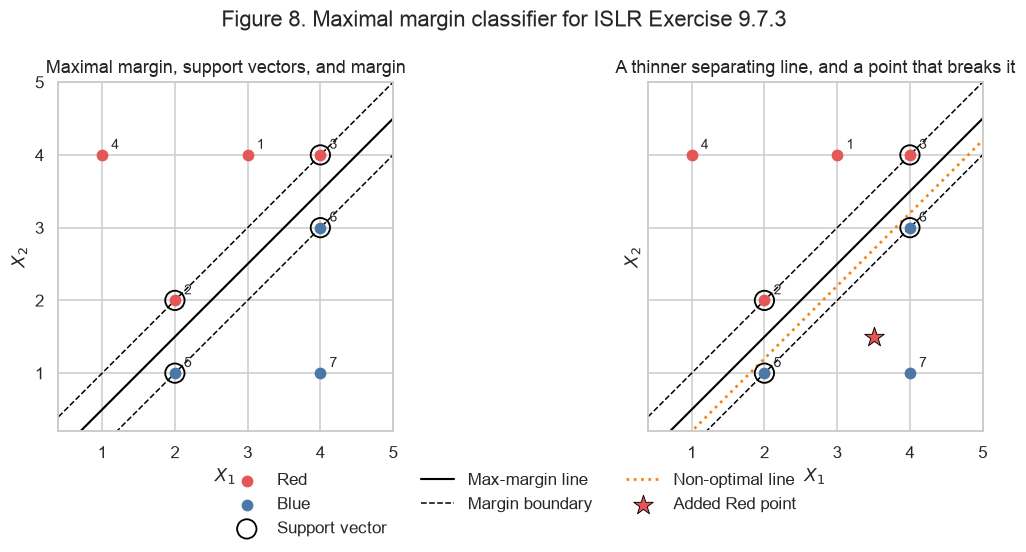

In [14]:
observations = np.array(
    [
        [3, 4],
        [2, 2],
        [4, 4],
        [1, 4],
        [2, 1],
        [4, 3],
        [4, 1],
    ],
    dtype=float,
)
is_red = np.array([True, True, True, True, False, False, False])
support = np.array([False, True, True, False, True, True, False])
line_x = np.linspace(0.4, 5.0, 200)

fig, axes = plt.subplots(1, 2, figsize=(11.2, 5.0), sharex=True, sharey=True)
for axis in axes:
    axis.scatter(
        observations[is_red, 0],
        observations[is_red, 1],
        c="#E45756",
        s=45,
        label="Red",
        zorder=3,
    )
    axis.scatter(
        observations[~is_red, 0],
        observations[~is_red, 1],
        c="#4C78A8",
        s=45,
        label="Blue",
        zorder=3,
    )
    axis.scatter(
        observations[support, 0],
        observations[support, 1],
        facecolors="none",
        edgecolors="black",
        s=160,
        linewidths=1.2,
        label="Support vector",
        zorder=4,
    )
    for index, (x1, x2) in enumerate(observations, start=1):
        axis.annotate(str(index), (x1, x2), textcoords="offset points", xytext=(6, 4), fontsize=9)
    axis.plot(line_x, line_x - 0.5, color="black", linewidth=1.4, label="Max-margin line")
    axis.plot(line_x, line_x, color="black", linestyle="--", linewidth=1, label="Margin boundary")
    axis.plot(line_x, line_x - 1, color="black", linestyle="--", linewidth=1)
    axis.set_xlabel(r"$X_1$")
    axis.set_ylabel(r"$X_2$")
    axis.set_xlim(0.4, 5.0)
    axis.set_ylim(0.2, 5.0)
    axis.set_aspect("equal")

axes[1].plot(
    line_x,
    line_x - 0.8,
    color="#F58518",
    linestyle=":",
    linewidth=1.8,
    label="Non-optimal line",
)
axes[1].scatter(
    [3.5],
    [1.5],
    marker="*",
    s=180,
    c="#E45756",
    edgecolors="black",
    linewidths=0.6,
    label="Added Red point",
    zorder=5,
)
axes[0].set_title("Maximal margin, support vectors, and margin")
axes[1].set_title("A thinner separating line, and a point that breaks it")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False)
fig.suptitle("Figure 8. Maximal margin classifier for ISLR Exercise 9.7.3")
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()


## References

- James, G., Witten, D., Hastie, T., and Tibshirani, R. *An Introduction to Statistical Learning*. Exercises 6.8.3, 6.8.5, 8.4.5, and 9.7.3. The homework numbers the Chapter 6 exercises as 6.6.3 and 6.6.5.
- Chawla, N. V., Bowyer, K. W., Hall, L. O., and Kegelmeyer, W. P. (2002). SMOTE: Synthetic Minority Over-sampling Technique. *Journal of Artificial Intelligence Research*, 16, 321–357.
- Chen, T., and Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*.
- scikit-learn documentation for `RandomForestClassifier`, in particular `class_weight="balanced_subsample"` and `oob_score`.
- imbalanced-learn documentation for `SMOTE`.
- Lindgren, T., and Biteus, J. APS Failure at Scania Trucks. UCI Machine Learning Repository. The cost of a false positive is 10 and the cost of a false negative is 500.
